# Runner – étapes 1 à 3 sur PARHAF

Lance les scripts du dossier `MyDrive/pfe/code`. Le code ne se modifie pas ici : on l'édite dans les fichiers `.py` et le `config.yaml`.

| Section | GPU |
| --- | --- |
| 0. Installation | non |
| 1. Caractérisation du corpus | non |
| 2. Serveur vLLM | **oui** |
| 3. Baseline (étape 2) | **oui** pour la génération |
| 4. Jeu de référence (étape 3) | **oui** pour l'extraction |

Si Colab coupe : relancer la section 0, puis le serveur, puis le script interrompu. Il reprend là où il s'était arrêté.

## 0. Installation

In [1]:
import os
from google.colab import drive, userdata

drive.mount("/content/drive")
try:
    os.environ["HF_TOKEN"] = userdata.get("HF_TOKEN")   # Secrets Colab (icône clé)
except Exception:
    print("Pas de HF_TOKEN : téléchargements anonymes.")
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"

CODE_DIR = "/content/drive/MyDrive/pfe/code"
OUT_DIR = "/content/drive/MyDrive/pfe/outputs"   # doit correspondre à paths.output_dir du config.yaml
%cd {CODE_DIR}

Mounted at /content/drive
/content/drive/MyDrive/pfe/code


In [2]:
!pip install -q -r requirements.txt
!pip freeze > requirements.lock.txt   # versions exactes, à archiver avec chaque run
# Si PyTorch a été remplacé par l'installation de vLLM : Exécution > Redémarrer la session,
# puis relancer uniquement la cellule précédente (montage de Drive).

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
gradio 6.31.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
numba-cuda 0.28.2 requires cuda-core<1.0.0,>=0.5.1, but you have cuda-core 1.3.0 which is incompatible.
cudf-cu13 26.6.0 requires numba<0.65.0,>=0.60.0, but you have numba 0.65.0 which is incompatible.
cuml-cu13 26.6.0 requires numba<0.65.0,>=0.60.0, but you have numba 0.65.0 which is incompatible.


## Interface MLflow

Toutes les métriques des étapes 1 à 3 sont envoyées à MLflow par les scripts. Lancer cette section **après la section 0**, à n'importe quel moment : l'interface se met à jour quand on la recharge.

- **Experiments** → `pfe-step1-corpus`, `pfe-step2-baseline`, `pfe-step3-reference` ;
- dans un run de l'étape 2 : onglet *Model metrics* (courbes latence/tokens), *Traces* (prompt et sortie de chaque appel), *Evaluations* (métriques par patient) ;
- pour comparer deux variantes : cocher les runs puis **Compare**.

In [17]:
# Restaure la base sauvegardée sur Drive (nouvelle session) puis lance le serveur MLflow
import os, shutil
if not os.path.exists("/content/mlflow/mlflow.db") and os.path.exists("/content/drive/MyDrive/pfe/mlflow/mlflow.db"):
    shutil.copytree("/content/drive/MyDrive/pfe/mlflow", "/content/mlflow", dirs_exist_ok=True)
os.makedirs("/content/mlflow", exist_ok=True)

# --allowed-hosts / --x-frame-options : nécessaires derrière le proxy de Colab (MLflow >= 3.5)
!nohup mlflow server --backend-store-uri sqlite:////content/mlflow/mlflow.db --port 5000 \
    --allowed-hosts "*" --cors-allowed-origins "*" --x-frame-options NONE > /content/mlflow.log 2>&1 &

In [18]:
# Ouvre l'interface dans un nouvel onglet (attendre ~15 s après la cellule précédente)
from google.colab import output
output.serve_kernel_port_as_window(5000, path="/")
# Si l'onglet reste blanc : !tail -n 20 /content/mlflow.log

Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

In [22]:
import os, subprocess, yaml, mlflow

cfg = yaml.safe_load(open("config.yaml", encoding="utf-8"))

print("Section mlflow dans config.yaml :", cfg.get("mlflow"))

db = os.path.join(cfg["mlflow"]["local_dir"], "mlflow.db")

print("Base utilisée par les scripts :", db, "| existe :", os.path.exists(db))

print("Base lue par le serveur      :",

      subprocess.run("ps aux | grep '[m]lflow server'", shell=True,

                     capture_output=True, text=True).stdout.strip() or "SERVEUR NON LANCÉ")

mlflow.set_tracking_uri(f"sqlite:///{db}")

for exp in mlflow.search_experiments():

    runs = mlflow.search_runs([exp.experiment_id])

    print(f"\nExpérience '{exp.name}' : {len(runs)} run(s)")

    for _, r in runs.iterrows():

        n_metrics = sum(1 for c in runs.columns if c.startswith("metrics.") and r[c] == r[c])

        print(f"  - {r['tags.mlflow.runName']} | {n_metrics} métriques | statut {r['status']}")


Section mlflow dans config.yaml : {'local_dir': '/content/mlflow', 'drive_backup_dir': '/content/drive/MyDrive/pfe/mlflow', 'backup_every': 5, 'experiments': {'step1': 'pfe-step1-corpus', 'step2': 'pfe-step2-baseline', 'step3': 'pfe-step3-reference'}}
Base utilisée par les scripts : /content/mlflow/mlflow.db | existe : True
Base lue par le serveur      : root        4324  0.4  2.1 923696 285860 ?       Sl   14:33   0:06 /usr/bin/python3 /usr/local/bin/mlflow server --backend-store-uri sqlite:////content/mlflow/mlflow.db --port 5000 --allowed-hosts * --cors-allowed-origins * --x-frame-options NONE

Expérience 'pfe-step2-baseline' : 2 run(s)
  - test_mlflow_v1 | 32 métriques | statut FINISHED
  - test_3patients_v2 | 18 métriques | statut FINISHED

Expérience 'Default' : 0 run(s)


## 1. Caractérisation du corpus (étape 1)

In [6]:
!python step1_explore.py

config.json: 100% 737/737 [00:00<00:00, 3.73MB/s]
tokenizer_config.json: 100% 1.47k/1.47k [00:00<00:00, 369kB/s]
tokenizer.json: 100% 1.80M/1.80M [00:00<00:00, 138MB/s]

tokenizer.model: downloading bytes:   0% 0.00/493k [00:00<?, ?B/s]
tokenizer.model: downloading bytes: 100% 339k/339k [00:01<00:00, 207kB/s, 32.8kB/s  ]
tokenizer.model: reconstructing file: 100% 493k/493k [00:01<00:00, 301kB/s, 47.8kB/s  ]
special_tokens_map.json: 100% 414/414 [00:00<00:00, 2.38MB/s]
README.md: 100% 22.2k/22.2k [00:00<00:00, 37.2MB/s]

data/train-00000-of-00001.parquet: downloading bytes:  88% 8.11M/9.25M [00:01<00:00, 6.55MB/s]
data/train-00000-of-00001.parquet: downloading bytes: 100% 9.20M/9.20M [00:01<00:00, 6.22MB/s,  882kB/s  ]
data/train-00000-of-00001.parquet: reconstructing file: 100% 9.25M/9.25M [00:01<00:00, 6.26MB/s,  888kB/s  ]
Generating train split: 100% 4254/4254 [00:00<00:00, 24226.03 examples/s]
# Étape 1 – Caractérisation de PARHAF

Patients : 4254 | Documents : 6185 | Coût fixe du 

# Étape 1 – Caractérisation de PARHAF

Patients : 4254 | Documents : 6185 | Coût fixe du prompt : 177 tokens | Tokens par mot : 2.57

## Par type de document
| type         |    n |   mots_median |   tokens_median |   tokens_p90 |   tokens_max |   pct_tient_256 |   pct_tient_512 |
|:-------------|-----:|--------------:|----------------:|-------------:|-------------:|----------------:|----------------:|
| CRH          | 3563 |         496   |          1278   |       2574   |         7889 |            67.5 |            55.2 |
| CRC          | 1079 |         232   |           534   |        989.4 |         7090 |            98.1 |            95.7 |
| CRO          |  889 |         220   |           557   |       1008.4 |         2629 |            97   |            95.6 |
| ANAPATH      |  433 |         261   |           739   |       1463.6 |         3065 |            92.4 |            86.8 |
| ACCOUCHEMENT |   74 |         201   |           515.5 |       1178.1 |         1367 |           100   |            98.6 |
| MATERNITE    |   74 |         117.5 |           321.5 |        548.4 |          620 |           100   |           100   |
| URGENCES     |   73 |         345   |           905   |       1315.2 |         1604 |           100   |            90.4 |

## Patients dont tous les documents tiennent dans la fenêtre (%)
- sortie réservée 256 : 60.7 %
- sortie réservée 512 : 46.7 %

## Remplissage de structured_abstract (%)
|                 |    0 |
|:----------------|-----:|
| abs_diagnostic  | 85   |
| abs_acte        | 24.2 |
| abs_mode_entree | 37.6 |
| abs_mode_sortie | 37.6 |
| abs_duree       | 83.1 |

## Combinaisons de documents par patient
| doc_types                       |   count |
|:--------------------------------|--------:|
| CRH                             |    2672 |
| CRC+CRH+CRO                     |     887 |
| ANAPATH                         |     421 |
| CRC                             |     192 |
| ACCOUCHEMENT+MATERNITE+URGENCES |      72 |
| ANAPATH+ANAPATH                 |       6 |
| ACCOUCHEMENT+CRH+MATERNITE      |       2 |
| CRH+CRO                         |       1 |
| CRH+CRO+URGENCES                |       1 |

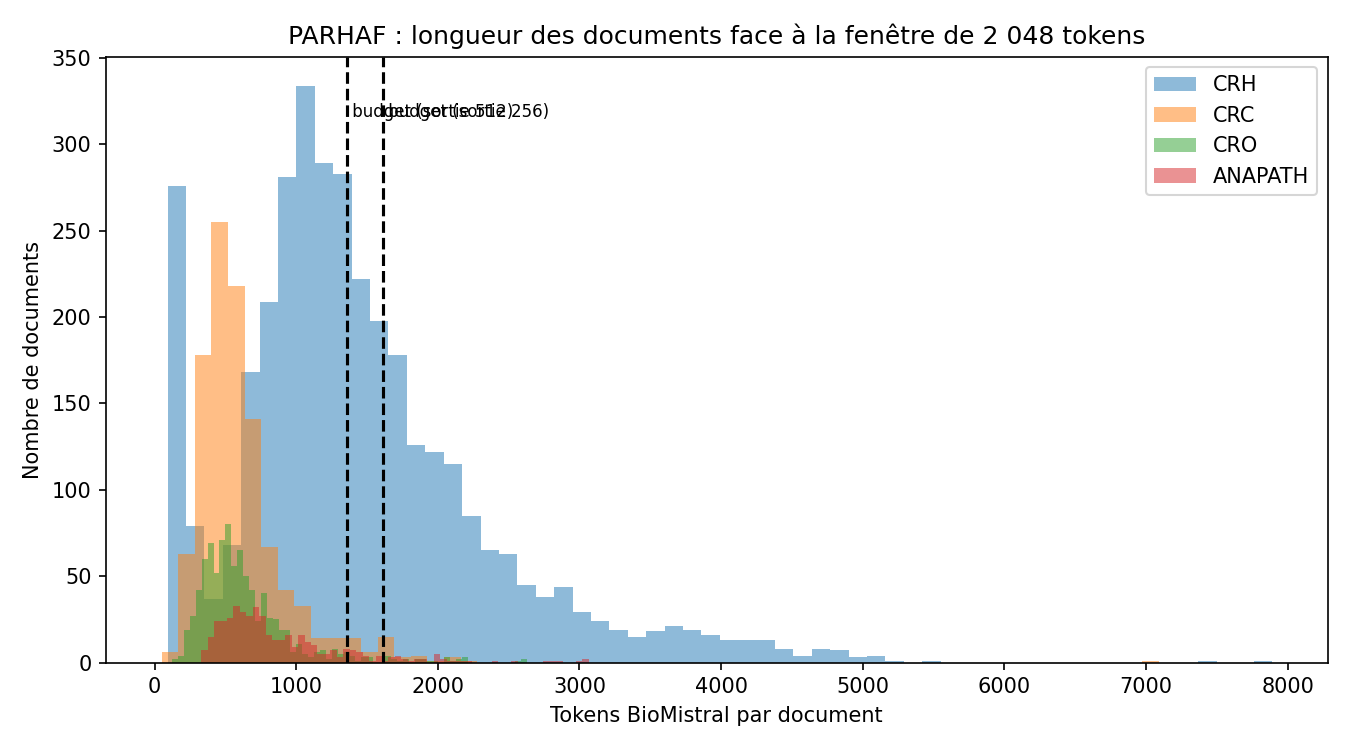

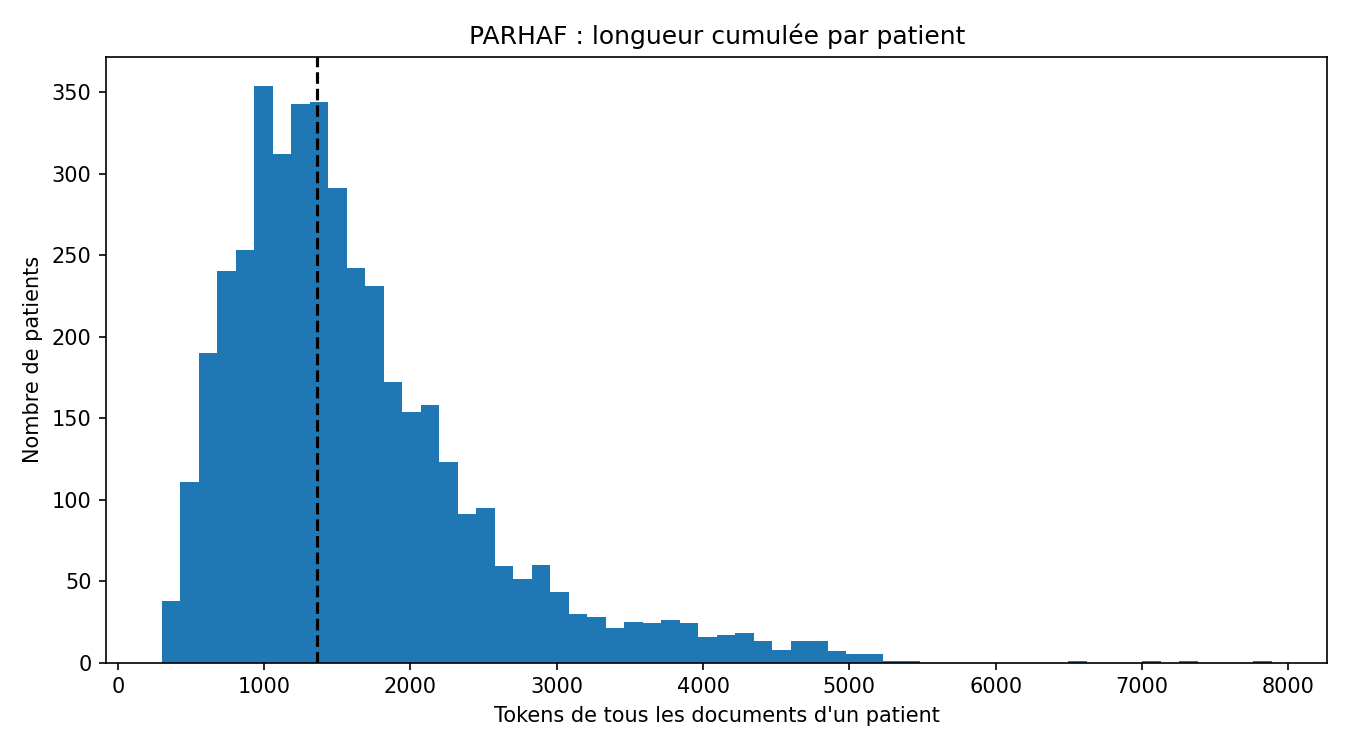

In [7]:
from IPython.display import Image, Markdown, display

display(Markdown(open(f"{OUT_DIR}/step1/summary.md", encoding="utf-8").read()))
display(Image(f"{OUT_DIR}/step1/tokens_par_type.png"))
display(Image(f"{OUT_DIR}/step1/tokens_par_patient.png"))

## 2. Serveur vLLM

Lancé en arrière-plan. Les scripts attendent eux-mêmes qu'il soit prêt (2 à 3 minutes). Ne pas ouvrir `Biomistrale.ipynb` dans la même session.

In [8]:
!nohup vllm serve BioMistral/BioMistral-7B-AWQ-QGS128-W4-GEMM \
    --quantization awq --max-model-len 2048 --enforce-eager --seed 42 \
    --port 8000 > /content/vllm.log 2>&1 &

In [9]:
# Vérifier l'état du serveur (relancer la cellule jusqu'à voir « Application startup complete »)
!tail -n 15 /content/vllm.log
!curl -s -o /dev/null -w "health: %{http_code}\n" http://localhost:8000/health

health: 000


## 3. Baseline CRH → résumé JSON (étape 2)

Commencer par tester avec `n_patients: 3` dans `config.yaml` et vérifier les premières lignes, puis repasser à 40.

In [23]:
!python step2_generate.py

40 patients sélectionnés, 0 déjà traités.
[1/40] CANCERO-ADULTE-00025 -> ok (30.619 s)
[2/40] CANCERO-ADULTE-00102 -> skipped_context_overflow (- s)
[3/40] CANCERO-ADULTE-00115 -> invalid_output (34.929 s)
[4/40] CANCERO-ADULTE-00129 -> ok (28.548 s)
[5/40] CANCERO-ADULTE-00138 -> skipped_context_overflow (- s)
[6/40] CARDIOLOGIE-00062 -> skipped_context_overflow (- s)
[7/40] CARDIOLOGIE-00116 -> skipped_context_overflow (- s)
[8/40] CHIR-ORTHO-ET-TRAUMATO-00024 -> ok (29.363 s)
[9/40] CHIR-ORTHO-ET-TRAUMATO-00073 -> ok (29.163 s)
[10/40] CHIR-ORTHO-ET-TRAUMATO-00253 -> ok (30.809 s)
[11/40] CHIR-CARDIO-VASC-00019 -> skipped_context_overflow (- s)
[12/40] CHIRURGIE-VISCERALE-00215 -> invalid_output (33.813 s)
[13/40] CHIRURGIE-VISCERALE-00354 -> ok (24.088 s)
[14/40] CHIRURGIE-VISCERALE-00365 -> ok (23.532 s)
[15/40] CHIRURGIE-VISCERALE-00383 -> ok (23.547 s)
[16/40] CHIRURGIE-VISCERALE-00510 -> ok (31.047 s)
[17/40] GYNECOLOGIE-00045 -> ok (33.517 s)
[18/40] GYNECOLOGIE-00294 -> ok (2

In [24]:
import json
import yaml

cfg = yaml.safe_load(open("config.yaml", encoding="utf-8"))
run_file = f"{OUT_DIR}/step2/{cfg['step2']['run_name']}.jsonl"
with open(run_file, encoding="utf-8") as f:
    first = json.loads(f.readline())
print("Statut :", first["status"], "| tokens estimés :", first["prompt_tokens_est"])
print(json.dumps(first.get("prediction") or first.get("raw_output"), ensure_ascii=False, indent=2))

Statut : ok | tokens estimés : 1414
{
  "diagnostic_principal": [
    {
      "code": "C34",
      "description": "Carcinome bronchique non à petites cellules"
    }
  ],
  "acte_principal": [
    {
      "code": "Z08",
      "description": "Consultation spécialisée: Oncologie thoracique"
    }
  ],
  "mode_entree": "Hospitalisation",
  "mode_sortie": "Sortie contre avis médical",
  "duree_sejour_jours": 1,
  "antecedents": [
    "Cancer de l'oropharynx",
    "Carcinome bronchique non à petites cellules"
  ],
  "traitements_sortie": [
    "Radiothérapie",
    "Carboplatine et Paclitaxel",
    "Atezolizumab",
    "Pemetrexed"
  ],
  "synthese": "Patiente âgée de 59 ans, suivie pour cancer de l'oropharynx traité par radiothérapie et chimiothérapie, puis pour carcinome bronchique non à petites cellules traité par radiothérapie et chimiothérapie, hospitalisée pour consultation spécialisée en oncologie thoracique et mise sous Pemetrexed. La patiente rapporte une douleur scapulaire gauche, a

In [25]:
!python step2_evaluate.py

{
  "run_name": "test_mlflow_v2",
  "n_patients": 40,
  "pct_json_valide": 50.0,
  "pct_sortie_invalide": 12.5,
  "pct_depassement_contexte": 37.5,
  "diag_code_exact_pct": 5.0,
  "diag_code_3car_pct": 20.0,
  "diag_sim_moyenne": 0.477,
  "acte_code_exact_pct": 0.0,
  "acte_sim_moyenne": 0.392,
  "entree_sim_moyenne": 0.25,
  "sortie_sim_moyenne": 0.282,
  "duree_exacte_pct": 38.9,
  "duree_plus_moins_1_pct": 88.9,
  "pct_nombres_non_sources": 11.8,
  "pct_codes_non_sources": 100.0,
  "latence_moyenne_s": 27.36,
  "latence_p90_s": 31.9,
  "tokens_entree_moyen": 987.5,
  "tokens_sortie_moyen": 408.0,
  "n_a_relire": 20
}
Evaluating:   0% 0/25 [00:00<?, ?it/s]2026/11/17 15:18:20 WARNING mlflow.tracing.export.mlflow_v3: Failed to send trace to MLflow backend: QueuePool limit of size 5 overflow 10 reached, connection timed out, timeout 30.00 (Background on this error at: https://sqlalche.me/e/21/3o7r)
2026/11/17 15:18:20 WARNING mlflow.tracing.export.mlflow_v3: Failed to send trace to MLfl

In [14]:
import pandas as pd

df = pd.read_csv(f"{OUT_DIR}/step2/{cfg['step2']['run_name']}_par_patient.csv")
df[df["a_relire"]]   # cas à vérifier à la main avant toute conclusion

,patient_id,specialty,diag_code_exact,diag_code_3car,diag_sim,acte_code_exact,acte_code_3car,acte_sim,entree_sim,sortie_sim,...,n_nombres,n_nombres_non_sources,nombres_non_sources,n_codes,n_codes_non_sources,codes_non_sources,latence_s,tokens_entree,tokens_sortie,a_relire
0,CHIR-ORTHO-ET-TRAUMATO-00073,CHIR ORTHO ET TRAUMATO,False,False,0.442308,False,False,0.36036,NaN,NaN,...,7,2,"1, 60",2,2,"L697, Z030",35.501,583,456,True
1,NEUROLOGIE-00224,NEUROLOGIE,False,False,0.295652,NaN,NaN,NaN,NaN,NaN,...,5,0,NaN,3,3,"G90, G900, Z01",27.677,1471,415,True


## 4. Jeu de référence (étape 3)

1. Pré-extraction (GPU) ;
2. arrêt du serveur pour libérer le GPU ;
3. correction manuelle des fichiers `outputs/step3_gold/*.json` selon le guide du README ;
4. validation (sans GPU, à relancer autant de fois que nécessaire).

In [ ]:
!python step3_extract.py

In [ ]:
# Arrêter le serveur quand la génération est finie (libère le GPU et le quota Colab)
!pkill -f "vllm serve" && echo "Serveur arrêté"

In [ ]:
!python step3_validate.py

## Fin de session

Les scripts sauvegardent déjà la base MLflow sur Drive. Cette cellule force une dernière sauvegarde (utile après un arrêt manuel).

In [ ]:
import shutil
shutil.copytree("/content/mlflow", "/content/drive/MyDrive/pfe/mlflow", dirs_exist_ok=True)
print("Base MLflow sauvegardée sur Drive.")